# Solución de sistemas de ecuaciones diferenciales

## Método de Euler

Considere una Ecuación Diferencial Ordinaria (*EDO*) de la forma

$$
 \dot{y} = f(x),
$$ (eqn:EDOform)
donde $f$ es una función. La solución general a la Ec. {eq}`eqn:EDOform` está dada por la siguiente expresión

$$
 y = \int f(x)\mathrm{d}x + c,
$$
donde $c$ es una constante arbitraria. Para obtener una solución, dependemos de un valor inicial de la forma

$$
 y\left(x_{0}\right) = y_{0}.
$$

Para la mayoría de problemas de valor inicial no es posible encontrar una solución exacta (analítica) ya que las ecuaciones son no lineales, discontinuas, o estocásticas. Por ejemplo, $\dot{y} = e^{{xy}^{4}}$. Por lo tanto, necesitamos de un método numérico para aproximar la solución.

Es posible aproximar el término del lado izquierdo de un problema de valor inicial $\frac{\mathrm{d}f}{\mathrm{d}x}$ utilizando el *teorema de Taylor* alrededor de un punto dado $x_{0}$

$$
 f\left(x_{1}\right) = f\left(x_{0}\right) + \left(x_{1}-x_{0}\right)\dot{f}\left(x_{0}\right) + \tau,
$$
donde $\tau$ es el error de truncamiento

$$
 \tau = \frac{\left(x_{1} - x_{0}\right)^{2}}{2!}\ddot{f}\left(\xi \right), \quad \xi\in\left[x_{0}, x_{1}\right].
$$

Recordando que $h = x_{1} - x_{0}$, las ecuación anterior queda definida como sigue

$$
 \dot{f}\left(x_{0}\right) = \frac{f\left(x_{1}\right) - f\left(x_{0}\right)}{h} - \frac{h}{2}\ddot{f}\left(\xi\right)
$$

Es posible obtener el método de Euler directo utilizando una variación de la *interpolación de Lagrange* llamada *diferencia dividida*.

Podemos aproximar cualquier función $f(x)$ utilizando un polinomio de grado $P_{n}(x)$ y un término de error

$$
 \begin{aligned}
  f(x) &= P_{n}(x) + \text{error}, \\
  &= f\left(x_{0}\right) + f\left[x_{0}, x_{1}\right]\left(x - x_{0}\right) + f\left[x_{0}, x_{1}, x_{2}\right]\left(x - x_{0}\right)\left(x - x_{1}\right), \\
  &+ \cdots + f\left[x_{0},\dots,x_{n}\right]\prod_{i=0}^{n-1}\left(x - x_{1}\right) + \text{error},
 \end{aligned}
$$
donde

$$
 \begin{aligned}
  f\left[x_{0}, x_{1}\right] &= \frac{f\left(x_{1}\right) - f\left(x_{0}\right)}{x_{1} - x_{0}}, \\
  f\left[x_{0}, x_{1}, x_{2}\right] &= \frac{f\left[x_{1},x_{2}\right] - f\left[x_{0},x_{1}\right]}{x_{2} - x_{0}}, \\
  f\left[x_{0}, x_{1}, \dots, x_{n}\right] &= \frac{f\left[x_{1},x_{2},\dots,x_{n}\right] - f\left[x_{0},x_{1},\dots,x_{n-1}\right]}{x_{n} - x_{0}}. \\
 \end{aligned}
$$

Derivando $P_{n}(x)$, tenemos

$$
 \begin{aligned}
  \dot{P}_{n}(x) &= f\left[x_{0},x_{1}\right] + f\left[x_{0},x_{1},x_{2}\right]\left\{\left(x - x_{0}\right) + \left(x - x_{1}\right) \right\}, \\
  &+ \cdots + f\left[x_{0},\dots,x_{n}\right]\sum_{i=0}^{n-1} \frac{\left(x - x_{0}\right)\dots\left(x - x_{n-1}\right)}{\left(x - x_{i}\right)},
 \end{aligned}
$$
por consiguiente el error se define como sigue

$$
 \text{error} = \left(x - x_{0}\right)\dots\left(x - x_{n}\right)\frac{f^{n+1}\left(\xi\right)}{\left(n + 1\right)!}.
$$

Definimos entonces la primer derivada como sigue

$$
 \dot{f}(x) = \left[x_{0}, x_{1}\right] = \frac{f\left(x_{1}\right) - f\left(x_{0}\right)}{x_{1} - x_{0}},
$$
lo que implica

$$
 \dot{f}(x) =  \frac{f\left(x_{1}\right) - f\left(x_{0}\right)}{x_{1} - x_{0}} + O\left(h\right), \quad \text{Euler},
$$

$$
 \dot{f}(x) =  \frac{f\left(x_{1}\right) - f\left(x_{-1}\right)}{x_{1} - x_{-1}} + O\left(h^{2}\right), \quad \text{Central}.
$$

Utilizando el mismo método, obtenemos una aproximación a la segunda derivada como sigue

$$
 \ddot{f}\left(x_{0}\right) = \frac{f_{2} - 2f_{1} + f_{0}}{h^{2}} + O\left(h^{2} \right),
$$

$$
 \ddot{f}\left(x_{0}\right) = \frac{f_{1} - 2f_{0} + f_{-1}}{h^{2}} + O\left(h^{2} \right), \quad \text{central}.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Suprimir advertencias menores de integración durante los bucles de optimización
import warnings
warnings.filterwarnings("ignore")

# Configurar el estilo de graficación para una mejor visualización
plt.style.use('ggplot')

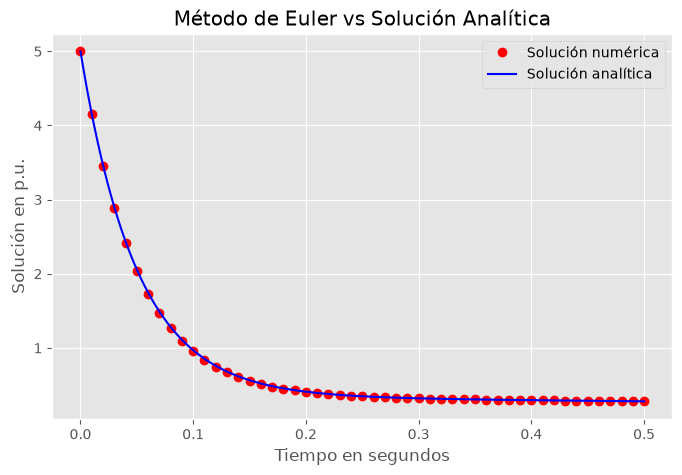

In [3]:
# Parámetros iniciales de la simulación
tfin = 0.5          # Tiempo de simulación
h = 0.001           # Paso de integración

# Se usa np.arange asegurando incluir el punto final tfin.
t = np.arange(0, tfin + h/2, h)
N = len(t)          # Número de muestras que se simulan.

# Inicialización del vector de la solución numérica con ceros.
y = np.zeros(N)
y[0] = 5            # Condición inicial (y(0) = 5).

# Ciclo iterativo del Método de Euler para la EDO
# Ecuación diferencial: y' + 20y = 7*exp(-0.5*t)  ->  y' = -20y + 7*exp(-0.5*t)
for k in range(1, N):
    # k-1 representa el índice anterior en la indexación basada en 0 de Python.
    f_val = -20 * y[k - 1] + 7 * np.exp(-0.5 * t[k - 1])
    y[k] = y[k - 1] + h * f_val

# Solución analítica exacta
y1 = (181 / 39) * np.exp(-20 * t) + (14 / 39) * np.exp(-0.5 * t)

# Gráfica de la solución numérica y analítica
plt.figure(figsize=(8, 5))

# t[::10] y y[::10] equivale a tomar cada 10 elementos (t(1:10:N)) para no saturar los puntos 'or' (círculos rojos).
plt.plot(t[::10], y[::10], 'or', label='Solución numérica')
plt.plot(t, y1, '-b', label='Solución analítica')

# Configuración de etiquetas y leyenda
plt.legend()
plt.xlabel('Tiempo en segundos')
plt.ylabel('Solución en p.u.')
plt.title('Método de Euler vs Solución Analítica')
plt.grid(True)

# Mostrar la gráfica
plt.show()

**Ejemplo**

Aplique la fórmula de Euler a la ecuación de primer orden con una entrada oscilante

$$
 \dot{y} = \sin(x), \quad 0 \leq x \leq 10.
$$


**Ejemplo**

El crecimiento demográfico simple está descrito por una ecuación diferencial de primer orden de la forma

$$
 \dot{y} = \varepsilon y,
$$
cuya solución exacta está dada por

$$
 y = Ce^{\varepsilon x}.
$$

Dada la siguiente condición inicial

$$
 y\left(0\right) = 1,
$$
con una tasa de cambio de $\varepsilon = 0.5$, la solución analítica queda expresada como sigue

$$
 y = e^{0.5 x}.
$$

Aplique la fórmula de Euler para obtener una solución aproximada.

## Método de Runge-Kutta

El método de Runge-Kutta (*RK*) está relacionado con la expansión de la *serie de Taylor*, con la diferencia de que no es necesaria la diferenciación de $f$.

Los métodos RK se escriben de la siguiente forma

$$
 w_{n+1} = w_{n} + hF\left(t,w,h; f\right), \quad n\geq 0,
$$
donde el error de truncamiento está definido por

$$
 T_{n}\left(y\right) = y\left(t_{n+1}\right) - y\left(t_{n}\right) - hF\left(t_{n},y\left(t_{n}\right),h;f\right),
$$
tal que el error está dado como sigue $\tau_{n}\left(y\right)$

$$
 T_{n} = h\tau_{n}\left(y\right).
$$

Reescribiendo términos, tenemos

$$
 y\left(t_{n+1}\right) = y\left(t_{n}\right) - hF \left(t_{n}, y\left(t_{n}\right), h; f \right) + h\tau_{n}\left(y\right).
$$

Considere el método explícito de un paso

$$
 \frac{w_{i+1} - w_{i}}{h} = F\left(f, t_{i}, w_{i},h \right),
$$
con

$$
 F\left(f, t, y, h \right) = a_{0}k_{1} + a_{1}k_{2},
$$

$$
 F\left(f, t, y, h \right) = a_{0}\left(t, y \right) + a_{1}\left(t + \alpha_{1}, y + \beta_{1} \right),
$$
donde $\alpha_{0} + \alpha_{1} = 1$.

````{important}
 En la formulación del *método de Runge-Kutta* existe un parámetro libre. En este caso, $\alpha_{0}$.
````

````{prf:theorem}
 :label: thm:polynomial
 Sea $f\left(t,y\right)$ y todas sus derivadas parciales de orden menor o igual a $n+1$ continuas sobre $D = \left\{ \left(t,y \right) | a \leq t \leq b, c \leq y \leq d \right\}$ y sea $\left(t_{0}, y_{0}\right)\in D$ para cada $\left(t, y\right) \in D$, $\exists \xi \in \left(t, t_{0}\right)$ y $\mu \in \left(y, y_{0}\right)$ con

 $$
  f\left(t,y\right) = P_{n} \left(t,y\right) + R_{n}\left(t,y\right),
 $$
 donde

 $$
  \begin{aligned}
   P_{n}\left(t,y\right) &= f\left(t_{0},y_{0}\right) + \left[ \left(t - t_{0}\right) \frac{\partial f}{\partial t}\left(t_{0},y_{0}\right) + \left(y - y_{0}\right)\frac{\partial f}{\partial y}\left(t_{0}, y_{0}\right) \right] \\
   &+ \left[ \frac{\left(t -t_{0}\right)^{2}}{2}\frac{\partial^{2}f}{\partial t^{2}}\left(t_{0}, y_{0}\right) + \left(y - y_{0}\right)\left(t - t_{0}\right) \frac{\partial^{2} f}{\partial y\partial t}\left(t_{0}, y_{0}\right) \right. \\
   &+ \left. \frac{\left(y - y_{0}\right)^{2}}{2}\frac{\partial^{2} f}{\partial y^{2}} \left(t_{0}, y_{0} \right) \right] \\
   &+ \dots + \\
   &+ \left[ \frac{1}{n!} \sum_{j=0}^{n} \binom{n}{j} \left(t - t_{0}\right)^{n-j}\left(y - y_{0}\right)^{j}\frac{\partial^{n} f}{\partial y^{j}\partial t^{n-j}}\left(t_{0},y_{0}\right) \right].
  \end{aligned}
 $$
````

Podemos utilizar el {prf:ref}`thm:polynomial` para encontrar los valores $a_{1}$, $\alpha_{1}$ y $\beta_{1}$ considerando que $\alpha_{1}f\left(t+\alpha_{1}, y + \beta_{1}\right)$ aproxima a Taylor de segundo orden

$$
 f\left(t,y\right) + \frac{h}{2}\dot{f}\left(t,y\right)
$$
con un error no mayor a $O\left(h^{2}\right)$.

Utilizando

$$
 \dot{f}\left(t,y\right) = \frac{\partial f}{\partial t}\left(y,t\right) + \frac{\partial f}{\partial y}\left(t,y\right)\dot{y}(t),
$$
la expresión de Taylor de segundo orden se puede escribir como sigue

$$
 f\left(t,y\right) + \frac{h}{2}\frac{\partial f}{\partial t}\left(y,t\right) + \frac{h}{2}\frac{\partial f}{\partial y}\left(t,y\right)f\left(t,y\right).
$$

Expandiendo $\alpha_{1}f\left(t+\alpha_{1}, y + \beta_{1}\right)$ y su *polinomio de Taylor* de grado uno alrededor de $\left(t,y\right)$, tenemos

$$
 \alpha_{1}f\left(t+\alpha_{1}, y + \beta_{1}\right) = \alpha_{1}f\left(t, y\right) + a_{1}\alpha_{1}\frac{\partial f}{\partial t}\left(t, y\right) + a_{1}\beta_{1}\frac{\partial f}{\partial y} + a_{1}R_{1}\left(t + \alpha_{1}, y + \beta_{1}\right),
$$
donde

$$
 R_{1}\left(t + \alpha_{1}, y + \beta_{1} \right) = \frac{\alpha_{1}^{2}}{2}\frac{\partial^{2}f}{\partial t^{2}}\left(\xi, \mu \right) + \alpha_{1}\beta_{1} \frac{\partial^{2}f}{\partial t\partial y}\left(\xi,\mu \right) + \frac{\beta_{1}^{2}}{2}\frac{\partial^{2}f}{\partial y^{2}}\left(\xi,\mu \right),
$$
para algún $\xi \in \left[t,t + \alpha_{1} \right]$ y $\mu \in \left[y,y + \beta_{1} \right]$.

Los métodos de orden mayor se obtienen de forma similar. Por ejemplo, Runge-Kutta de tercer orden se expresa como sigue

$$
 \frac{w_{i+1} - w_{i}}{h} = F\left(f, t_{i}, w_{i}, h \right),
$$
con

$$
 F\left(f, t, w, h \right) = a_{0}k_{1} + a_{1}k_{2} + a_{2}k_{3},
$$
donde

$$
 a_{0} + a_{1} + a_{2} = 1,
$$

$$
 \begin{aligned}
  k_{1} &= f\left(t_{i}, w_{i} \right), \\
  k_{2} &= f\left(t_{i} + \alpha_{1}h, t_{i} + \beta_{11}k_{1} \right), \\
  k_{3} &= f\left(t_{i} + \alpha_{2}h, t_{i} + \beta_{21}k_{1} + \beta_{22}k_{2} \right).
 \end{aligned}
$$

Escogiendo $\alpha_{2} = 1$, $\beta_{11} = \frac{1}{2}$, obtenemos la siguiente ecuación

$$
 w_{i+1} = w_{i} + \frac{h}{6}\left(k_{1} + 4k_{2} + k_{3} \right),
$$
donde

$$
 \begin{aligned}
  k_{1} &= f\left(t_{i}, w_{i} \right), \\
  k_{2} &= f\left(t_{n} + \frac{h}{2}, w_{n} + \frac{h}{2}k_{1} \right), \\
  k_{3} &= f\left(t_{n} + h, w_{n} - hk_{1} + 2hk_{2} \right). \\
 \end{aligned}
$$

Para obtener el método de Runge-Kutta de cuarto orden, consideramos

$$
 \begin{aligned}
  w_{0} &= \alpha, \\
  k_{1} &= hf\left(t_{i}, w_{i} \right), \\
  k_{2} &= hf\left(t_{i} + \frac{h}{2}, w_{i} + \frac{k_{1}}{2} \right), \\
  k_{3} &= hf\left(t_{i} + \frac{h}{2}, w_{i} + \frac{k_{2}}{2} \right), \\
  k_{4} &= hf\left(t_{i+1}, w_{i} + k_{3} \right), \\
  w_{i+1} &= w_{i} + \frac{1}{6}\left(k_{1} + 2k_{2} + 2k_{3} + k_{4} \right).
 \end{aligned}
$$

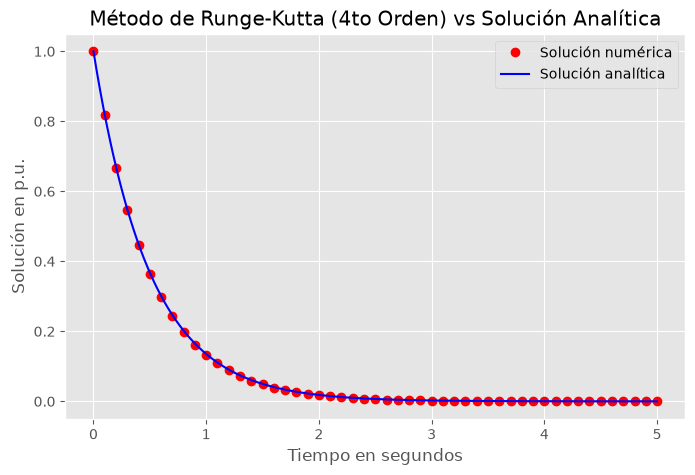

In [4]:
# Parámetros iniciales de la simulación
tfin = 5            # Tiempo de observación.
h = 0.01            # Paso de integración.

# Vector de tiempos de integración (equivalente a 0:h:tfin en MATLAB).
t = np.arange(0, tfin + h/2, h)
N = len(t)          # Número de muestras que se simulan.

# Inicialización de vectores para la solución y los coeficientes RK4.
y = np.zeros(N)
k1 = np.zeros(N)
k2 = np.zeros(N)
k3 = np.zeros(N)
k4 = np.zeros(N)

# Condición inicial (y(0) = 1).
y[0] = 1

# Ciclo iterativo del Método de Runge-Kutta de 4to Orden
# Ecuación diferencial: y' + 2y = 0  ->  y' = -2y
for k in range(1, N):
    k1[k] = h * (-2 * y[k - 1])
    k2[k] = h * (-2 * (y[k - 1] + 0.5 * h * k1[k]))
    k3[k] = h * (-2 * (y[k - 1] + 0.5 * h * k2[k]))
    k4[k] = h * (-2 * (y[k - 1] + h * k3[k]))
    
    # Cálculo del siguiente valor de y usando el promedio ponderado de los coeficientes
    y[k] = y[k - 1] + (1 / 6) * (k1[k] + 2 * k2[k] + 2 * k3[k] + k4[k])


# Solución analítica exacta
y1 = np.exp(-2 * t)


# Gráfica de la solución numérica y analítica
plt.figure(figsize=(8, 5))

# t[::10] y y[::10] seleccionan uno de cada diez puntos para graficar círculos rojos sin saturar.
plt.plot(t[::10], y[::10], 'or', label='Solución numérica')
plt.plot(t, y1, '-b', label='Solución analítica')

# Configuración de ejes, leyenda y etiquetas
plt.legend()
plt.xlabel('Tiempo en segundos')
plt.ylabel('Solución en p.u.')
plt.title('Método de Runge-Kutta (4to Orden) vs Solución Analítica')
plt.grid(True)

# Mostrar la gráfica
plt.show()